In [2]:
import sys
sys.path.append("..")

import time, os
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, precision_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from src.pipeline import buat_pipeline, muat_data, pilih_skenario

MODEL = {
    "Baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=42),
                      {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [5, 20]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_estimators=100,
                                             random_state=42, n_jobs=-1),
                      {"model__max_depth": [10, None], "model__min_samples_leaf": [5]}),
    "SVM": (SVC(class_weight="balanced", random_state=42),
            {"model__C": [0.1, 1, 10], "model__gamma": ["scale"]}),
    "kNN": (KNeighborsClassifier(), {"model__n_neighbors": [5, 15, 31]}),
}

N_REPEATS = 1   # percobaan pertama; nanti boleh dinaikkan jadi 2
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=42)
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
SKOR = {"f1": "f1", "recall": "recall",
        "precision": make_scorer(precision_score, zero_division=0),
        "roc_auc": "roc_auc"}

In [3]:
X_train, y_train = muat_data("../data/processed/train.csv")

hasil, baris = {}, []
for dengan in (False, True):
    skenario = "dengan akademik" if dengan else "tanpa akademik"
    Xs = pilih_skenario(X_train, dengan)
    for nama, (model, grid) in MODEL.items():
        t = time.time()
        pipe = buat_pipeline(model, Xs)
        est = GridSearchCV(pipe, grid, cv=inner, scoring="f1", n_jobs=-1) if grid else pipe
        r = cross_validate(est, Xs, y_train, cv=outer, scoring=SKOR, n_jobs=1)
        hasil[(skenario, nama)] = r
        baris.append({"skenario": skenario, "model": nama,
                      "F1": r["test_f1"].mean(), "F1_std": r["test_f1"].std(),
                      "recall": r["test_recall"].mean(), "precision": r["test_precision"].mean(),
                      "ROC_AUC": r["test_roc_auc"].mean()})
        print(f"{skenario} | {nama:14s} | F1 {r['test_f1'].mean():.3f} | {time.time()-t:.0f} dtk", flush=True)

tabel = pd.DataFrame(baris).round(3)
tabel

tanpa akademik | Baseline       | F1 0.000 | 0 dtk
tanpa akademik | Decision Tree  | F1 0.599 | 25 dtk
tanpa akademik | Random Forest  | F1 0.634 | 18 dtk
tanpa akademik | SVM            | F1 0.644 | 19 dtk
tanpa akademik | kNN            | F1 0.469 | 4 dtk
dengan akademik | Baseline       | F1 0.000 | 1 dtk
dengan akademik | Decision Tree  | F1 0.748 | 4 dtk
dengan akademik | Random Forest  | F1 0.769 | 12 dtk
dengan akademik | SVM            | F1 0.783 | 26 dtk
dengan akademik | kNN            | F1 0.682 | 12 dtk


,skenario,model,F1,F1_std,recall,precision,ROC_AUC
0,tanpa akademik,Baseline,0.000,0.000,0.000,0.000,0.500
1,tanpa akademik,Decision Tree,0.599,0.025,0.620,0.584,0.763
2,tanpa akademik,Random Forest,0.634,0.014,0.679,0.595,0.813
3,tanpa akademik,SVM,0.644,0.006,0.657,0.632,0.818
4,tanpa akademik,kNN,0.469,0.020,0.373,0.632,0.698
5,dengan akademik,Baseline,0.000,0.000,0.000,0.000,0.500
6,dengan akademik,Decision Tree,0.748,0.018,0.790,0.710,0.870
7,dengan akademik,Random Forest,0.769,0.020,0.793,0.747,0.907
8,dengan akademik,SVM,0.783,0.010,0.781,0.785,0.916
9,dengan akademik,kNN,0.682,0.025,0.581,0.827,0.839


In [4]:
def selang_kepercayaan(skor, k=5, alpha=0.05):
    J = len(skor)
    se = np.sqrt((1 / J + 1 / (k - 1)) * np.var(skor, ddof=1))
    t = stats.t.ppf(1 - alpha / 2, J - 1)
    return skor.mean() - t * se, skor.mean() + t * se

ci = []
for (skenario, nama), r in hasil.items():
    lo, hi = selang_kepercayaan(r["test_f1"])
    ci.append({"skenario": skenario, "model": nama, "F1_CI_bawah": lo, "F1_CI_atas": hi})

tabel_akhir = tabel.merge(pd.DataFrame(ci), on=["skenario", "model"]).round(3)
os.makedirs("../results", exist_ok=True)
tabel_akhir.to_csv("../results/hasil_cv.csv", index=False)
tabel_akhir

,skenario,model,F1,F1_std,recall,precision,ROC_AUC,F1_CI_bawah,F1_CI_atas
0,tanpa akademik,Baseline,0.000,0.000,0.000,0.000,0.500,0.000,0.000
1,tanpa akademik,Decision Tree,0.599,0.025,0.620,0.584,0.763,0.546,0.652
2,tanpa akademik,Random Forest,0.634,0.014,0.679,0.595,0.813,0.604,0.664
3,tanpa akademik,SVM,0.644,0.006,0.657,0.632,0.818,0.632,0.656
4,tanpa akademik,kNN,0.469,0.020,0.373,0.632,0.698,0.427,0.510
5,dengan akademik,Baseline,0.000,0.000,0.000,0.000,0.500,0.000,0.000
6,dengan akademik,Decision Tree,0.748,0.018,0.790,0.710,0.870,0.710,0.785
7,dengan akademik,Random Forest,0.769,0.020,0.793,0.747,0.907,0.728,0.810
8,dengan akademik,SVM,0.783,0.010,0.781,0.785,0.916,0.762,0.803
9,dengan akademik,kNN,0.682,0.025,0.581,0.827,0.839,0.630,0.735


In [9]:
MODEL_FINAL = "Random Forest"   # sesuai aturan yang sudah ditulis

In [10]:
import json
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score, confusion_matrix
from src.pipeline import bersihkan_nama_kolom, TARGET

test = bersihkan_nama_kolom(pd.read_csv("../data/processed/test.csv"))
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

model, grid = MODEL[MODEL_FINAL]
uji, prediksi = {}, {}
for dengan in (False, True):
    skenario = "dengan akademik" if dengan else "tanpa akademik"
    Xs, Xt = pilih_skenario(X_train, dengan), pilih_skenario(X_test, dengan)
    gs = GridSearchCV(buat_pipeline(model, Xs), grid,
                      cv=StratifiedKFold(5, shuffle=True, random_state=42),
                      scoring="f1", n_jobs=-1).fit(Xs, y_train)
    pred = gs.predict(Xt)
    skor = gs.decision_function(Xt) if hasattr(gs, "decision_function") else gs.predict_proba(Xt)[:, 1]
    prediksi[skenario] = pred
    uji[skenario] = {
        "model": MODEL_FINAL, "param_terbaik": {k: str(v) for k, v in gs.best_params_.items()},
        "F1": round(f1_score(y_test, pred), 3), "recall": round(recall_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred), 3), "ROC_AUC": round(roc_auc_score(y_test, skor), 3),
        "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
    }

os.makedirs("../results", exist_ok=True)
with open("../results/hasil_uji_sekali.json", "w") as f:
    json.dump(uji, f, indent=2)
pd.DataFrame(uji).T

,model,param_terbaik,F1,recall,precision,ROC_AUC,confusion_matrix
tanpa akademik,Random Forest,"{'model__max_depth': '10', 'model__min_samples...",0.65,0.701,0.607,0.816,"[[472, 129], [85, 199]]"
dengan akademik,Random Forest,"{'model__max_depth': '10', 'model__min_samples...",0.795,0.806,0.784,0.921,"[[538, 63], [55, 229]]"


In [12]:
d = X_test.copy()
d["y"], d["pred"] = y_test.values, prediksi["tanpa akademik"]
d["hasil"] = np.select(
    [(d.y == 1) & (d.pred == 1), (d.y == 1) & (d.pred == 0), (d.y == 0) & (d.pred == 1)],
    ["TP (dropout, tertangkap)", "FN (dropout, terlewat)", "FP (salah alarm)"], "TN (benar tidak dropout)")

print(d["hasil"].value_counts())
d.groupby("hasil")[["Tuition fees up to date", "Scholarship holder", "Debtor",
                    "Age at enrollment", "Admission grade"]].mean().round(2)

hasil
TN (benar tidak dropout)    472
TP (dropout, tertangkap)    199
FP (salah alarm)            129
FN (dropout, terlewat)       85
Name: count, dtype: int64


,Tuition fees up to date,Scholarship holder,Debtor,Age at enrollment,Admission grade
hasil,,,,,
"FN (dropout, terlewat)",0.99,0.22,0.01,20.27,126.78
FP (salah alarm),0.90,0.08,0.14,29.60,127.84
TN (benar tidak dropout),0.99,0.41,0.04,19.82,128.28
"TP (dropout, tertangkap)",0.51,0.05,0.26,29.89,123.28


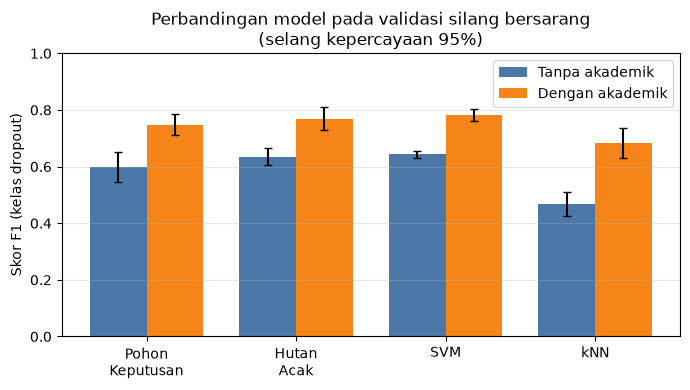

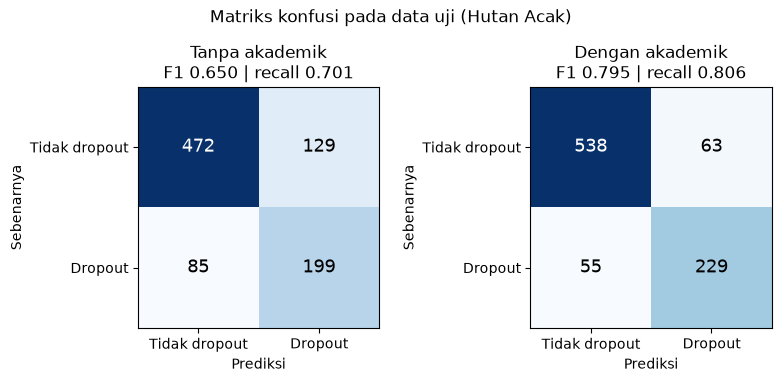

In [21]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../report/gambar", exist_ok=True)
cv = pd.read_csv("../results/hasil_cv.csv")
with open("../results/hasil_uji_sekali.json") as f:
    uji = json.load(f)

NAMA_MODEL = {"Decision Tree": "Pohon\nKeputusan", "Random Forest": "Hutan\nAcak", "SVM": "SVM", "kNN": "kNN"}
model = list(NAMA_MODEL)
skenario = ["tanpa akademik", "dengan akademik"]
warna = {"tanpa akademik": "#4c78a8", "dengan akademik": "#f58518"}
x = np.arange(len(model)); lebar = 0.38

# Gambar 1: F1 hasil validasi silang bersarang dengan selang kepercayaan
fig, ax = plt.subplots(figsize=(7, 4))
for i, s in enumerate(skenario):
    d = cv[(cv.skenario == s) & (cv.model.isin(model))].set_index("model").loc[model]
    err = [d.F1 - d.F1_CI_bawah, d.F1_CI_atas - d.F1]
    ax.bar(x + (i - 0.5) * lebar, d.F1, lebar, yerr=err, capsize=3, label=s.capitalize(), color=warna[s])
ax.set_xticks(x); ax.set_xticklabels([NAMA_MODEL[m] for m in model])
ax.set_ylabel("Skor F1 (kelas dropout)"); ax.set_ylim(0, 1)
ax.set_title("Perbandingan model pada validasi silang bersarang\n(selang kepercayaan 95%)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("../report/gambar/f1_cv.png", dpi=200); plt.show()

# Gambar 2: matriks konfusi data uji
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, s in zip(axes, skenario):
    cm = np.array(uji[s]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13,
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Tidak dropout", "Dropout"]); ax.set_yticklabels(["Tidak dropout", "Dropout"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
    ax.set_title(f"{s.capitalize()}\nF1 {uji[s]['F1']:.3f} | recall {uji[s]['recall']:.3f}")
nama_final = NAMA_MODEL.get(uji[skenario[0]]["model"], uji[skenario[0]]["model"]).replace("\n", " ")
fig.suptitle(f"Matriks konfusi pada data uji ({nama_final})")
fig.tight_layout(); fig.savefig("../report/gambar/confusion_matrix.png", dpi=200); plt.show()

tanpa akademik
Biaya kuliah lunas      0.0626
Menunggak               0.0174
Penerima beasiswa       0.0170
Usia saat mendaftar     0.0108
Pekerjaan ibu           0.0043
Kelas siang/malam       0.0036
Program studi           0.0034
Tingkat pengangguran    0.0030 



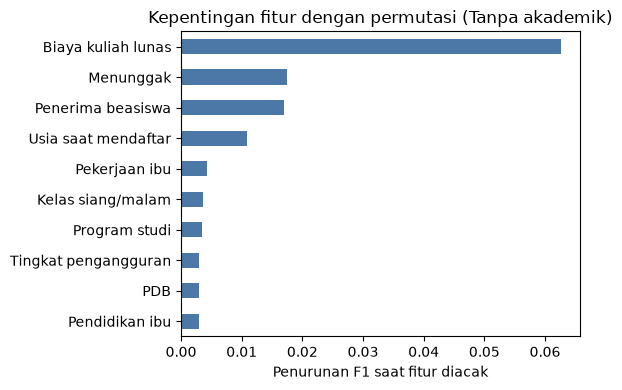

dengan akademik
Biaya kuliah lunas         0.0503
Sem. 2: MK lulus           0.0438
Sem. 1: MK lulus           0.0223
Sem. 2: nilai rata-rata    0.0150
Menunggak                  0.0124
Usia saat mendaftar        0.0090
Pendidikan ibu             0.0057
Sem. 2: jumlah evaluasi    0.0055 



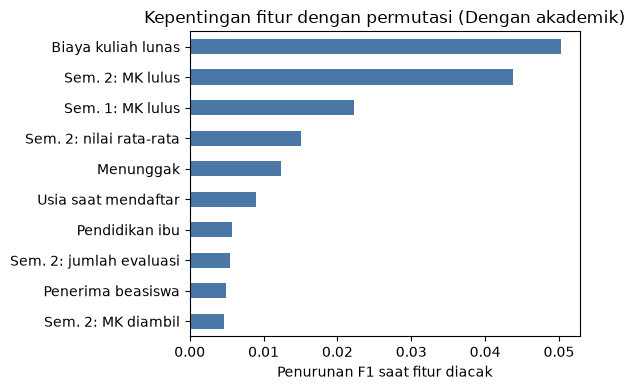

In [22]:
import sys
sys.path.append("..")

import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from src.pipeline import muat_data, pilih_skenario, buat_pipeline

os.makedirs("../report/gambar", exist_ok=True)
X_train, y_train = muat_data("../data/processed/train.csv")

for dengan in (False, True):
    nama = "dengan akademik" if dengan else "tanpa akademik"
    Xs = pilih_skenario(X_train, dengan)
    X_fit, X_val, y_fit, y_val = train_test_split(Xs, y_train, test_size=0.25,
                                                  stratify=y_train, random_state=42)
    rf = RandomForestClassifier(class_weight="balanced", n_estimators=100,
                                min_samples_leaf=5, random_state=42, n_jobs=-1)
    pipe = buat_pipeline(rf, Xs).fit(X_fit, y_fit)
    r = permutation_importance(pipe, X_val, y_val, scoring="f1", n_repeats=5,
                               random_state=42, n_jobs=1)
    imp = pd.Series(r.importances_mean, index=Xs.columns).sort_values(ascending=False)
    imp = imp.rename(index=NAMA_ID)
    print(nama); print(imp.head(8).round(4).to_string(), "\n")

    ax = imp.head(10)[::-1].plot.barh(figsize=(6, 4), color="#4c78a8")
    ax.set_xlabel("Penurunan F1 saat fitur diacak")
    ax.set_title(f"Kepentingan fitur dengan permutasi ({nama.capitalize()})")
    plt.tight_layout()
    plt.savefig(f"../report/gambar/perm_importance_{nama.replace(' ', '_')}.png", dpi=200)
    plt.show()

In [18]:
import os
import pandas as pd

NAMA_ID = {
    "Marital status": "Status pernikahan", "Application mode": "Jalur pendaftaran",
    "Application order": "Urutan pilihan pendaftaran", "Course": "Program studi",
    "Daytime/evening attendance": "Kelas siang/malam", "Previous qualification": "Kualifikasi sebelumnya",
    "Previous qualification (grade)": "Nilai kualifikasi sebelumnya", "Nacionality": "Kewarganegaraan",
    "Mother's qualification": "Pendidikan ibu", "Father's qualification": "Pendidikan ayah",
    "Mother's occupation": "Pekerjaan ibu", "Father's occupation": "Pekerjaan ayah",
    "Admission grade": "Nilai masuk", "Displaced": "Merantau (pindah dari rumah)",
    "Educational special needs": "Kebutuhan pendidikan khusus", "Debtor": "Menunggak",
    "Tuition fees up to date": "Biaya kuliah lunas", "Gender": "Jenis kelamin",
    "Scholarship holder": "Penerima beasiswa", "Age at enrollment": "Usia saat mendaftar",
    "International": "Mahasiswa internasional",
    "Curricular units 1st sem (credited)": "Sem. 1: MK diakui",
    "Curricular units 1st sem (enrolled)": "Sem. 1: MK diambil",
    "Curricular units 1st sem (evaluations)": "Sem. 1: jumlah evaluasi",
    "Curricular units 1st sem (approved)": "Sem. 1: MK lulus",
    "Curricular units 1st sem (grade)": "Sem. 1: nilai rata-rata",
    "Curricular units 1st sem (without evaluations)": "Sem. 1: MK tanpa evaluasi",
    "Curricular units 2nd sem (credited)": "Sem. 2: MK diakui",
    "Curricular units 2nd sem (enrolled)": "Sem. 2: MK diambil",
    "Curricular units 2nd sem (evaluations)": "Sem. 2: jumlah evaluasi",
    "Curricular units 2nd sem (approved)": "Sem. 2: MK lulus",
    "Curricular units 2nd sem (grade)": "Sem. 2: nilai rata-rata",
    "Curricular units 2nd sem (without evaluations)": "Sem. 2: MK tanpa evaluasi",
    "Unemployment rate": "Tingkat pengangguran", "Inflation rate": "Tingkat inflasi", "GDP": "PDB",
}

os.makedirs("../results", exist_ok=True)
pd.Series(NAMA_ID).rename_axis("kolom_asli").reset_index(name="nama_indonesia") \
  .to_csv("../results/kamus_kolom.csv", index=False)

# simpan kamus sebagai tabel untuk lampiran laporan
os.makedirs("../results", exist_ok=True)
pd.Series(NAMA_ID).rename_axis("kolom_asli").reset_index(name="nama_indonesia") \
  .to_csv("../results/kamus_kolom.csv", index=False)

In [20]:
imp = pd.Series(r.importances_mean, index=Xs.columns).sort_values(ascending=False)
imp = imp.rename(index=NAMA_ID)          # <-- baris baru: terjemahkan label